> **AI-use disclosure.** This notebook was developed with the help of **Claude Code (Anthropic)** in VS Code.
> * **AI-generated / AI-assisted:** code structure, the data-processing and model code (in `src/` and the cells below),
>   plotting code, and first drafts of the explanatory markdown.
> * **Done by the student (B. G. M. Prabuddhi):** choice of the problem and the Sri Lankan dataset, making and approving
>   the data and modelling decisions, reviewing the code, running the notebook, checking the outputs, and interpreting the results.
>
> Full details: [`AI_DISCLOSURE.md`](../AI_DISCLOSURE.md).

# 04 · Boosting ensembles: AdaBoost, Gradient Boosting, XGBoost, LightGBM, CatBoost

**Goal.** Train, tune and evaluate five boosting ensembles on exactly the same data as the bagging models, using
**early stopping on the 2022 validation year**, and save the best one.

**How boosting works (and why it differs from bagging).** Bagging trains strong, deep trees *independently* and averages
them (variance reduction). Boosting trains *weak, shallow* trees **sequentially**: each new tree focuses on what the
current ensemble still gets wrong, so the ensemble's **bias** falls step by step. The danger is the opposite of
bagging's: too many rounds start fitting noise, which is why we stop early.
* **AdaBoost (R2):** re-weights the training rows so that badly predicted rows get more attention in the next tree.
* **Gradient Boosting:** each tree fits the *negative gradient* of the loss (for squared error, simply the residuals),
  scaled by a learning rate.
* **XGBoost:** gradient boosting with a regularised objective (L2 on leaf weights), second-order (Newton) steps and
  fast histogram splits.
* **LightGBM:** grows trees *leaf-wise* (always splits the leaf with the largest gain) on histograms, so it is very fast.
* **CatBoost:** *ordered boosting* (each row's residual is computed by a model that has not seen that row), which
  reduces target leakage/over-fitting, plus symmetric (oblivious) trees.

Procedure per model: (1) tune with `RandomizedSearchCV` + `TimeSeriesSplit(3)` on 2007–2021; (2) choose the number of
rounds by early stopping on 2022 (native `eval_set` for XGBoost/LightGBM/CatBoost, `staged_predict` for
AdaBoost/GradientBoosting); (3) refit on 2007–2021 with that many rounds; (4) score on 2023–2026.

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))            # make `src` importable from the notebook
warnings.filterwarnings("ignore")

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src import config, viz
viz.set_style()
pd.set_option("display.width", 140, "display.max_columns", 30)

import time
from src import models as M, evaluate as E, features as F
cfg, splits, feats = M.load_data()
tr, va, te = splits["train"], splits["val"], splits["test"]
print(f"train {len(tr):,} | val {len(va):,} | test {len(te):,} rows | log1p target: {cfg['use_log_target']}")

train 19,731 | val 1,328 | test 4,854 rows | log1p target: True


## 1. Tune, early-stop, fit and evaluate

In [2]:
BOOSTING = ["AdaBoost", "Gradient Boosting", "XGBoost", "LightGBM", "CatBoost"]
fitted, info = {}, {}
for name in BOOSTING:
    t0 = time.time()
    params, cv_mae, _ = M.tune(name, cfg, tr, feats)
    rounds = M.early_stopping_rounds(name, params, cfg, tr, va, feats)
    pipe, fit_s = M.fit_timed(M.build_final(name, params, cfg, n_rounds=rounds), tr, feats)
    E.record_result(name, "Boosting", te, pipe.predict(te[feats]), fit_s, val=va, val_pred=pipe.predict(va[feats]))
    M.save_best_params(name, params, rounds, cv_mae=cv_mae)
    fitted[name] = pipe
    info[name] = {"rounds (early stopping)": rounds, "CV MAE": round(cv_mae, 3), "total time (s)": round(time.time() - t0)}
    print(f"   -> {rounds} rounds chosen on validation")

display(pd.DataFrame(info).T)
res = E.results_table()
res[res.family.isin(["Baseline", "Bagging", "Boosting"])].round(3)

AdaBoost: best CV MAE 15.281 in 155s -> {'loss': 'linear', 'learning_rate': 0.1, 'estimator__max_depth': 5}


   -> 10 rounds chosen on validation


Gradient Boosting: best CV MAE 14.477 in 116s -> {'subsample': 0.7, 'min_samples_leaf': 20, 'max_depth': 4, 'learning_rate': 0.1}


   -> 35 rounds chosen on validation


XGBoost: best CV MAE 14.881 in 36s -> {'subsample': 0.9, 'reg_lambda': 1, 'min_child_weight': 1, 'max_depth': 3, 'learning_rate': 0.05, 'colsample_bytree': 0.8}


   -> 71 rounds chosen on validation


... (2 outputs left out)

CatBoost: best CV MAE 14.418 in 30s -> {'learning_rate': 0.1, 'l2_leaf_reg': 3, 'depth': 4}


   -> 69 rounds chosen on validation


,rounds (early stopping),CV MAE,total time (s)
AdaBoost,10.0,15.281,209.0
Gradient Boosting,35.0,14.477,161.0
XGBoost,71.0,14.881,37.0
LightGBM,104.0,14.577,23.0
CatBoost,69.0,14.418,33.0


,model,family,MAE,RMSE,R2,sMAPE,MAE_vs_naive_pct,RMSE_vs_naive_pct,MAE_normal,MAE_outbreak,val_MAE,train_time_s
0,Naive (last week),Baseline,14.949,37.586,0.867,46.210,0.000,0.000,7.432,21.062,11.547,0.00
1,Seasonal naive (last year),Baseline,37.753,95.695,0.140,79.931,-152.540,-154.600,17.630,54.118,20.114,0.00
2,Extra Trees,Bagging,14.506,39.089,0.856,43.813,2.963,-3.997,6.199,21.262,10.340,4.98
3,Random Forest,Bagging,14.520,37.472,0.868,44.349,2.874,0.304,6.073,21.389,10.393,8.49
4,Bagging (Decision Trees),Bagging,14.701,38.281,0.862,44.465,1.659,-1.848,6.031,21.752,10.449,6.69
5,Gradient Boosting,Boosting,15.447,43.010,0.826,43.936,-3.327,-14.429,5.894,23.216,10.430,4.09
6,CatBoost,Boosting,15.714,44.105,0.817,44.693,-5.115,-17.343,6.139,23.501,10.562,0.60
7,AdaBoost,Boosting,16.021,47.361,0.789,45.136,-7.169,-26.006,6.327,23.904,10.484,1.74
8,XGBoost,Boosting,16.508,51.886,0.747,44.382,-10.425,-38.045,5.926,25.113,10.442,0.30
9,LightGBM,Boosting,18.593,50.949,0.756,46.669,-24.376,-35.553,5.983,28.849,10.576,0.48


## 2. Seeing bias reduction (and over-fitting) round by round
For Gradient Boosting we track the error after every boosting round on the **training** data and on the **2022
validation** data. Training error keeps falling (bias goes down); validation error falls, flattens and eventually
rises: the point where extra rounds only fit noise. Early stopping picks the bottom of the validation curve.

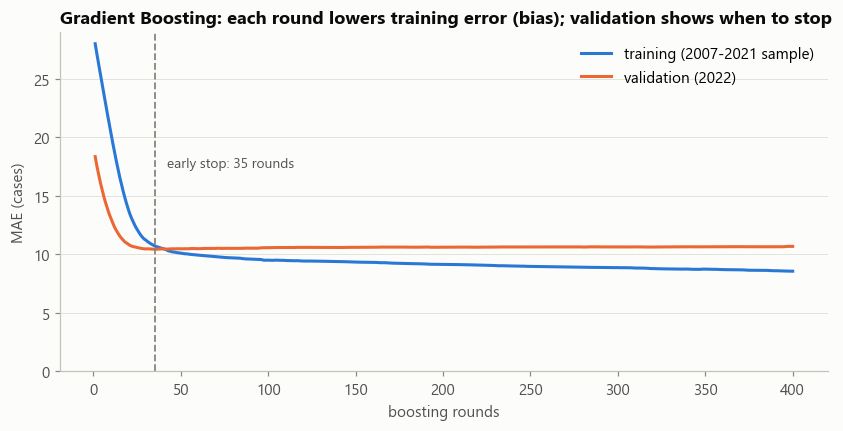

train MAE: round 1 28.0 -> round 400 8.6 | val MAE: best 10.43 at round 35, round 400 10.68


In [3]:
from sklearn.metrics import mean_absolute_error
gb_params, gb_rounds = M.load_best_params("Gradient Boosting")
long_gb = M.build_final("Gradient Boosting", gb_params, cfg, n_rounds=400).fit(tr[feats], tr.target)
inner, prep = long_gb.named_steps["model"].regressor_, long_gb.named_steps["prep"]
sub = tr.sample(5000, random_state=config.RANDOM_STATE)          # subset keeps this cell fast
curve = lambda X, y: [mean_absolute_error(y, np.clip(np.expm1(p), 0, None)) for p in inner.staged_predict(prep.transform(X))]
tr_curve, va_curve = curve(sub[feats], sub.target), curve(va[feats], va.target)

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(range(1, 401), tr_curve, color=viz.SERIES[0], label="training (2007-2021 sample)")
ax.plot(range(1, 401), va_curve, color=viz.SERIES[1], label="validation (2022)")
ax.axvline(gb_rounds, color=viz.MUTED, ls="--", lw=1.2)
ax.annotate(f"early stop: {gb_rounds} rounds", xy=(gb_rounds, max(va_curve) * 0.95), xytext=(8, 0),
            textcoords="offset points", color=viz.INK_2, fontsize=9)
ax.set_xlabel("boosting rounds"); ax.set_ylabel("MAE (cases)"); ax.set_ylim(0)
ax.set_title("Gradient Boosting: each round lowers training error (bias); validation shows when to stop")
ax.legend(); viz.save(fig, "boosting_rounds_curve"); plt.show()
print(f"train MAE: round 1 {tr_curve[0]:.1f} -> round 400 {tr_curve[-1]:.1f} | "
      f"val MAE: best {min(va_curve):.2f} at round {int(np.argmin(va_curve)) + 1}, round 400 {va_curve[-1]:.2f}")

## 3. Sensitivity check: did early stopping on a calm year hurt the outbreak forecasts?
2022 (validation) was a low-incidence year (mean 23.8 cases per region-week vs 54 in the 2023–2026 test period).
Early stopping on 2022 may therefore pick a model that is "tuned for calm weeks". Here each booster is refit with
the **full number of rounds used during CV tuning** (no early stopping) and scored on test.
*This is a diagnostic only:* the models we keep and compare are still the ones selected on validation.

In [4]:
default_rounds = {"AdaBoost": 200, "Gradient Boosting": 200, "XGBoost": 400, "LightGBM": 400, "CatBoost": 500}
ob = E.outbreak_mask(te)
naive_mae = E.regression_metrics(te.target, te.naive_pred)["MAE"]
rows = []
for name in BOOSTING:
    params, es_rounds = M.load_best_params(name)
    for label, n in [("early-stopped", es_rounds), ("full rounds (no early stop)", default_rounds[name])]:
        pipe = M.build_final(name, params, cfg, n_rounds=n).fit(tr[feats], tr.target)
        p = np.clip(pipe.predict(te[feats]), 0, None)
        rows.append({"model": name, "version": label, "rounds": n,
                     "val_MAE": E.regression_metrics(va.target, pipe.predict(va[feats]))["MAE"],
                     "test_MAE": E.regression_metrics(te.target, p)["MAE"],
                     "test_MAE_normal": np.abs(p - te.target)[~ob].mean(),
                     "test_MAE_outbreak": np.abs(p - te.target)[ob].mean()})
sens = pd.DataFrame(rows)
sens["test_vs_naive_pct"] = E.improvement(sens.test_MAE, naive_mae)
sens.round(3)

,model,version,rounds,val_MAE,test_MAE,test_MAE_normal,test_MAE_outbreak,test_vs_naive_pct
0,AdaBoost,early-stopped,10,10.484,16.021,6.327,23.905,-7.168
1,AdaBoost,full rounds (no early stop),200,10.832,17.588,6.434,26.659,-17.652
2,Gradient Boosting,early-stopped,35,10.430,15.447,5.893,23.216,-3.327
3,Gradient Boosting,full rounds (no early stop),200,10.612,16.714,5.788,25.600,-11.807
4,XGBoost,early-stopped,71,10.442,16.508,5.926,25.113,-10.425
5,XGBoost,full rounds (no early stop),400,10.529,15.572,5.636,23.653,-4.168
6,LightGBM,early-stopped,104,10.576,18.593,5.983,28.849,-24.376
7,LightGBM,full rounds (no early stop),400,10.503,17.468,5.999,26.794,-16.846
8,CatBoost,early-stopped,69,10.562,15.714,6.139,23.501,-5.115
9,CatBoost,full rounds (no early stop),500,10.635,18.378,5.857,28.561,-22.937


## 4. What does XGBoost rely on?

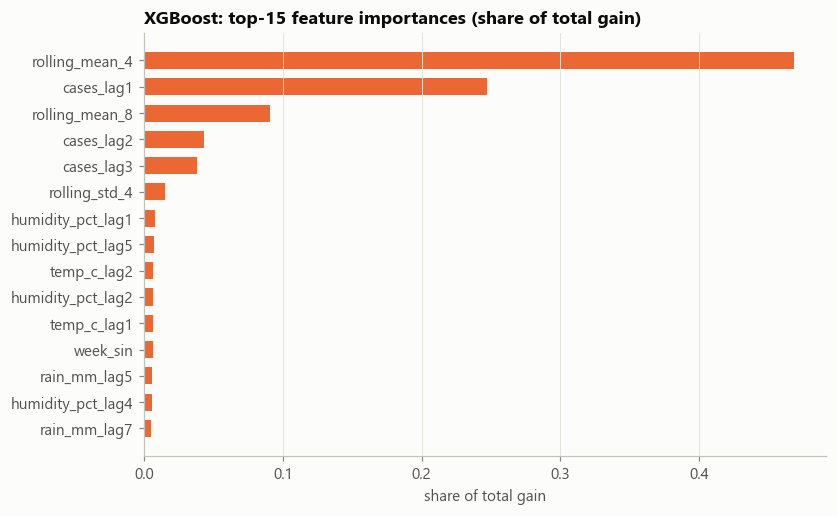

In [5]:
xgb_pipe = fitted["XGBoost"]
names = xgb_pipe.named_steps["prep"].get_feature_names_out()
gain = pd.Series(xgb_pipe.named_steps["model"].regressor_.get_booster().get_score(importance_type="gain"))
gain.index = [names[int(k[1:])] for k in gain.index]          # f0, f1, ... -> real names
imp = (gain / gain.sum()).sort_values(ascending=False)
top = imp.head(15)[::-1]
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(top.index, top.values, color=viz.SERIES[1], height=0.65)
ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)
ax.set_title("XGBoost: top-15 feature importances (share of total gain)"); ax.set_xlabel("share of total gain")
viz.save(fig, "fi_xgboost"); plt.show()

## 5. Save the boosting models (best chosen on validation MAE)

In [6]:
boost = E.results_table().query("family == 'Boosting'")
best = boost.sort_values("val_MAE").iloc[0]["model"]
print("best boosting model by validation MAE:", best)
for name, pipe in fitted.items():                   # boosted models are small, so all are kept
    fname = M.slug(name) + ".joblib"
    M.save_model(pipe, fname)
    M.register(M.slug(name), name, fname)
M.register("boosting_best", best, M.slug(best) + ".joblib")

best boosting model by validation MAE: Gradient Boosting
saved models/adaboost.joblib (0.0 MB)
saved models/gradient_boosting.joblib (0.0 MB)
saved models/xgboost.joblib (0.0 MB)
saved models/lightgbm.joblib (0.2 MB)
saved models/catboost.joblib (0.0 MB)


## Key findings

* **On validation (2022) boosting looks as good as bagging** (val MAE 10.43–10.58 vs 10.34–10.45), but **on the
  outbreak-heavy test period every boosting model is worse than the naive baseline**: Gradient Boosting 15.45 (−3.3%),
  CatBoost 15.71 (−5.1%), AdaBoost 16.02 (−7.2%), XGBoost 16.51 (−10.4%), LightGBM 18.59 (−24.4%), vs naive 14.95 and
  bagging 14.51–14.70.
* **Boosting wins calm weeks and loses outbreak weeks.** Normal-week MAE is the best of any family (5.89–6.33 vs naive
  7.43), but outbreak-week MAE is 23.2–28.8 vs 21.06 for naive. Outbreak weeks carry most of the absolute error, so the
  overall ranking flips.
* **Bias reduction is visible round by round:** Gradient Boosting's training MAE falls from 28.0 (1 round) to 8.6 (400
  rounds), while validation MAE is lowest at round 35 (10.43) and then rises (10.68 at round 400), classic over-fitting
  that early stopping prevents.
* **Early stopping on a calm year is only part of the problem:** with full rounds instead of early-stopped ones, XGBoost
  (16.51 → 15.57) and LightGBM (18.59 → 17.47) improve but stay worse than naive, while AdaBoost, Gradient Boosting and
  CatBoost get worse. Notebook 07 identifies the main cause: the log1p target's retransformation bias in outbreak weeks.
* **Same features drive both families:** XGBoost puts most of its gain on recent cases, like RF.
* **Speed and size:** boosted models train in 0.3–4 s (forests 5–8 s) and are tiny on disk (≤ 0.2 MB vs ~15 MB).
* Best boosting model on validation: **Gradient Boosting** (val MAE 10.430).